# 23 - Calibrated Tri-Window Phonetic Attention & Dual-Motion (5-Channel) Spatiotemporal VSR
## Tai Phake Visual Speech Recognition (VSR) Project — Experiment 23

---

### 📌 Strategic Mission & Kinematic Motivation

This notebook implements **Experiment 23**, introducing two foundational spatiotemporal innovations calibrated directly from exhaustive kinematic frame-by-frame analysis across all 1,100 video utterances of the Tai Phake numerical digit dataset:

1. **Empirical Calibrated Tri-Window Boundaries (`ONSET=(0, 10)`, `NUCLEUS=(7, 19)`, `CODA=(13, 30)`)**:
   - In Experiment 22, the hypothetical windows were set to `ONSET=(0, 12)`, `NUCLEUS=(9, 21)`, and `CODA=(18, 30)`.
   - **The Kinematic Diagnostic Discovery**:
     - Across all 100 utterances of $d_{10}$ (*Sip*), the active bilabial closure actually initiates at **Frame 11** and finishes sealing at **Frames 14..17**! From Frame 18 to 29, the lips remain in a completely stationary sealed rest state ($|Y_t - Y_{t-1}| \approx 0$).
     - Because `CODA_WINDOW` began at Frame 18, it completely missed the dynamic closing trajectory (Frames 11..17)!
     - Similarly, for $d_7$ (*Chit*), the tongue-tip contact with the alveolar ridge occurs at **Frames 13..18**.
   - **The Calibrated Window Specification**:
     - **Onset Window (Frames $0..10$)** $\to$ Consonant friction, dental posture, and bilabial onset.
     - **Nucleus Window (Frames $7..19$)** $\to$ Core vowel steady-state trajectory and peak vertical/horizontal oral aperture.
     - **Coda Window (Frames $13..30$)** $\to$ Complete terminal closure gesture (Frames 13..17) plus sealed steady-state coda (Frames 18..29).

2. **Dual-Motion 5-Channel Stream ($[R, G, B, \Delta^{\text{abs}}_t, \Delta^{\text{signed}}_t]$)**:
   - **Why Both Motion Streams?**
     - **Channel 3 — Absolute Optical Energy ($\Delta^{\text{abs}}_t = |Y_t - Y_{t-1}|$ from NB19)**: Captures unsigned velocity magnitude. Dominates high-speed ballistic closures ($d_0$ *Pau*, $d_8$ *Pet*, $d_{10}$ *Sip*), where velocity magnitude is maximum regardless of direction.
     - **Channel 4 — Signed Centered Polarity ($\Delta^{\text{signed}}_t = \text{clip}(127.5 + 0.5(Y_t - Y_{t-1}), 0, 255)$ from NB22)**: Preserves velocity polarity (mouth opening $>127.5$ vs closing $<127.5$), resolving vowel release from dental closures ($d_4$ vs $d_7$).
     - By supplying BOTH channels into a 5-channel tensor $(30, 96, 96, 5)$, the network is equipped with simultaneous access to both ballistic energy magnitude AND directional polarity!

3. **Utterance Speaker Neutralizer (`UtteranceSpeakerNeutralizer`)**:
   - Subtracts a learned fraction of the utterance temporal mean $F_t - \sigma(\alpha)\bar{F}$, stripping static facial morphology and skin tone to rescue difficult unseen validation speakers ($S35$, $s45$).

4. **1x1 Dual-Motion Stem Adapter**:
   - Maps 5 input channels $\to$ 3 channels with smart initialization:
     - Identity on RGB channels ($W_{0,0}=1, W_{1,1}=1, W_{2,2}=1$)
     - $+0.10$ contribution on Channel 3 (Absolute Motion)
     - $+0.10$ contribution on Channel 4 (Signed Motion)
   - Preserves ImageNet pretrained feature activations immediately at Step 0.

5. **Two-Stage Training & Snapshot Ensembling**:
   - Stage 1: Warmup with frozen EfficientNet-B0 (15–30 epochs) with Categorical Focal Loss ($\gamma=2.0, \alpha=0.25$, label smoothing $0.05$).
   - Stage 2: Fine-tuning top 20% spatial blocks under Cosine Annealing, saving top 5 snapshots.
   - Evaluated under 4-View Test-Time Augmentation (TTA).


## 1. System Environment & Reproducibility
Configuring deterministic random seeds across Python, NumPy, and TensorFlow.


In [1]:
# Section 1: Environment & Setup
import os
import sys
import re
import json
import time
import random
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
import keras
from keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 80)
print("SYSTEM ENVIRONMENT & REPRODUCIBILITY")
print("=" * 80)
print(f"Python Version     : {sys.version.split()[0]}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"GPUs Available     : {len(tf.config.list_physical_devices('GPU'))}")
print(f"Deterministic Seed : {SEED}")
print("=" * 80)


SYSTEM ENVIRONMENT & REPRODUCIBILITY
Python Version     : 3.12.13
TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
GPUs Available     : 0
Deterministic Seed : 42


## 2. Configuration & Hyperparameters
Defining 5-channel video dimensions, calibrated phonetic Tri-Window boundaries, Focal Loss parameters, and training schedules.


In [2]:
# Section 2: Configuration & Hyperparameters
DATASET_MODE = "80_20"

# Sequence & Tensor Specifications
NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 5  # RGB (0:3) + Absolute Motion (3) + Signed Motion (4)
BATCH_SIZE = 16

# Spatiotemporal Architecture Hyperparameters
PROJECTION_DIM = 256
GRU_UNITS = 128           # Bidirectional -> 256 features per frame
GRU_DROPOUT = 0.20
HEAD_DROPOUT = 0.40

# Kinematically Calibrated Phonetic Tri-Window Boundaries
ONSET_WINDOW = (0, 10)    # Frames 0..9   : Consonant friction, dental posture, bilabial onset
NUCLEUS_WINDOW = (7, 19)  # Frames 7..18  : Vowel steady-state & peak oral aperture
CODA_WINDOW = (13, 30)    # Frames 13..29 : Complete terminal closure (13..17) + sealed coda (18..29)

# Categorical Focal Loss Hyperparameters
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25
LABEL_SMOOTHING = 0.05

# Coda-Protected Cadence Jitter Augmentation
JITTER_DIGIT_IDS = [1, 2, 4, 7, 9, 10]
JITTER_PROBABILITY = 0.35
JITTER_MAX_DROP = 1       # Strictly max 1 frame, dropped between indices 2..12

# Snapshot Ensembling Parameters
TOP_K_SNAPSHOTS = 5

# Two-Stage Training Schedule
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 30
STAGE1_PATIENCE = 7

STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 25
STAGE2_PATIENCE = 8
FINE_TUNE_FRACTION = 0.20 # Fine-tune top 20% of EfficientNet-B0 with BatchNorm frozen

# Vocabulary Specification
DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
DIGIT_NAMES = {
    "d0": "Pau (0)", "d1": "Nung (1)", "d2": "Saung (2)", "d3": "Sam (3)",
    "d4": "Si (4)", "d5": "Ha (5)", "d6": "Hok (6)", "d7": "Chit (7)",
    "d8": "Pet (8)", "d9": "Kao (9)", "d10": "Sip (10)"
}
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print("=" * 80)
print("EXPERIMENT 23: CALIBRATED TRI-WINDOW DUAL-MOTION HYPERPARAMETERS")
print("=" * 80)
print(f"Input Tensor Shape          : ({NUM_FRAMES}, {FRAME_HEIGHT}, {FRAME_WIDTH}, {FRAME_CHANNELS}) [5-Channel]")
print(f"Calibrated Tri-Windows      : Onset={ONSET_WINDOW}, Nucleus={NUCLEUS_WINDOW}, Coda={CODA_WINDOW}")
print(f"Concatenated Head Dimension : 3 x 256 = 768 features")
print(f"Focal Loss                  : gamma={FOCAL_GAMMA}, alpha={FOCAL_ALPHA}, label_smoothing={LABEL_SMOOTHING}")
print(f"Snapshot Ensembling         : Top {TOP_K_SNAPSHOTS} Validation Checkpoints + 4-View TTA")
print("=" * 80)


EXPERIMENT 23: CALIBRATED TRI-WINDOW DUAL-MOTION HYPERPARAMETERS
Input Tensor Shape          : (30, 96, 96, 5) [5-Channel]
Calibrated Tri-Windows      : Onset=(0, 10), Nucleus=(7, 19), Coda=(13, 30)
Concatenated Head Dimension : 3 x 256 = 768 features
Focal Loss                  : gamma=2.0, alpha=0.25, label_smoothing=0.05
Snapshot Ensembling         : Top 5 Validation Checkpoints + 4-View TTA


## 3. Directory Paths Configuration
Configuring paths to active processed frames in `data/processed/` and dedicated experiment artifacts in `results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20/`.


In [3]:
# Section 3: Directory Paths Configuration
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"

RESULTS_DIR = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_calibrated_triwindow_dual_motion_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SNAPSHOT_DIR = RESULTS_DIR / "snapshots"
SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root     : {PROJECT_ROOT}")
print(f"Train Data Dir   : {TRAIN_DIR}")
print(f"Val Data Dir     : {VAL_DIR}")
print(f"Results Output   : {RESULTS_DIR}")
print(f"Snapshots Output : {SNAPSHOT_DIR}")


Project Root     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading
Train Data Dir   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/train
Val Data Dir     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/val
Results Output   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20
Snapshots Output : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20/snapshots


## 4. Speaker Partition Diagnostics & Zero-Leakage Verification
Validating that training and validation speakers are strictly disjoint at the base speaker level.


In [4]:
# Section 4: Speaker Split Verification & Diagnostics
train_speakers = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

base_train_speakers = sorted(
    list({get_base_speaker(s) for s in train_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)
base_val_speakers = sorted(
    list({get_base_speaker(s) for s in val_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)

print("=" * 80)
print(f"SPEAKER PARTITION DIAGNOSTICS [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Training Base Speakers   ({len(base_train_speakers):2d}) : {base_train_speakers}")
print(f"Training Total Folders   ({len(train_speakers):2d})")
print(f"Validation Base Speakers ({len(base_val_speakers):2d}) : {base_val_speakers}")
print(f"Validation Total Folders ({len(val_speakers):2d})")
print("-" * 80)

overlap = set(base_train_speakers).intersection(set(base_val_speakers))
assert len(overlap) == 0, f"CRITICAL LEAKAGE DETECTED: Overlapping speakers: {overlap}"
print("[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!")
print("=" * 80)


SPEAKER PARTITION DIAGNOSTICS [Mode: 80_20]
Training Base Speakers   (24) : ['s1', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's12', 's13', 's14', 's15', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's30']
Training Total Folders   (80)
Validation Base Speakers ( 6) : ['s34', 'S35', 'S38', 's45', 's47', 's48']
Validation Total Folders (20)
--------------------------------------------------------------------------------
[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!


## 5. Manifest Indexing
Discovering all video utterance directories and indexing sequential frame paths.


In [5]:
# Section 5: Utterance Manifest Indexing
utterances = []

for split_name, split_dir, spk_list in [("train", TRAIN_DIR, train_speakers), ("val", VAL_DIR, val_speakers)]:
    for spk in spk_list:
        spk_path = split_dir / spk
        for digit_dir in sorted(spk_path.iterdir()):
            if not digit_dir.is_dir() or digit_dir.name.startswith("."):
                continue
            digit_name = digit_dir.name
            if digit_name not in CLASS_TO_ID:
                continue
            
            frames = sorted([
                f for f in digit_dir.iterdir()
                if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ])
            if len(frames) == 0:
                continue
                
            utterances.append({
                "speaker": spk,
                "base_speaker": get_base_speaker(spk),
                "digit": digit_name,
                "digit_id": CLASS_TO_ID[digit_name],
                "split": split_name,
                "raw_frame_count": len(frames),
                "frame_paths": frames
            })

df_manifest = pd.DataFrame(utterances)
manifest_csv_path = RESULTS_DIR / "utterance_manifest.csv"
df_manifest[["speaker", "base_speaker", "digit", "digit_id", "split", "raw_frame_count"]].to_csv(
    manifest_csv_path, index=False
)

print("=" * 80)
print("UTTERANCE MANIFEST SUMMARY")
print("=" * 80)
print(f"Total Utterances Indexed : {len(df_manifest):,}")
print(f"  Train Set              : {len(df_manifest[df_manifest['split']=='train']):,} utterances")
print(f"  Validation Set         : {len(df_manifest[df_manifest['split']=='val']):,} utterances")
print(f"Manifest CSV saved to    : {manifest_csv_path}")
print("=" * 80)


UTTERANCE MANIFEST SUMMARY
Total Utterances Indexed : 1,100
  Train Set              : 880 utterances
  Validation Set         : 220 utterances
Manifest CSV saved to    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20/utterance_manifest.csv


## 6. Dataloader Architecture: 5-Channel Dual-Motion & Calibrated Jitter
- **Channel 3 (Absolute Optical Motion $\Delta^{\text{abs}}_t$)**: $|Y_t - Y_{t-1}|$ measures optical motion energy magnitude (ballistic closure spikes).
- **Channel 4 (Signed Centered Motion $\Delta^{\text{signed}}_t$)**: $\text{clip}(127.5 + 0.5(Y_t - Y_{t-1}), 0, 255)$ encodes directional velocity polarity (opening $>127.5$ vs closing $<127.5$).
- **Calibrated Cadence Jitter**: Drops 1 frame strictly between indices $2..12$, fully protecting the vowel nucleus ($7..19$) and coda closure transition ($13..29$).


In [6]:
# Section 6: Frame Sampling, 5-Channel Dual-Motion, and RAM Tensor Loader

def sample_30_frame_paths(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

def compute_dual_motion_5ch(seq_rgb: np.ndarray) -> np.ndarray:
    """
    Computes a 5-channel spatiotemporal representation:
      - Channels 0..2: RGB color channels [0, 255]
      - Channel 3: Absolute optical velocity |Y_t - Y_{t-1}| (energy magnitude)
      - Channel 4: Signed centered velocity clip(127.5 + 0.5 * (Y_t - Y_{t-1}), 0, 255) (polarity)
    
    Args:
        seq_rgb: (T, H, W, 3) float32 in [0.0, 255.0]
    Returns:
        seq_5ch: (T, H, W, 5) float32
    """
    T, H, W, _ = seq_rgb.shape
    gray = (
        0.2989 * seq_rgb[..., 0] +
        0.5870 * seq_rgb[..., 1] +
        0.1140 * seq_rgb[..., 2]
    )[..., np.newaxis]
    
    # Channel 3: Absolute motion differences
    diff_abs = np.zeros((T, H, W, 1), dtype=np.float32)
    diff_abs[1:] = np.abs(gray[1:] - gray[:-1])
    
    # Channel 4: Signed centered motion differences
    diff_signed = np.full((T, H, W, 1), 127.5, dtype=np.float32)
    diff_signed[1:] = np.clip(127.5 + 0.5 * (gray[1:] - gray[:-1]), 0.0, 255.0)
    
    return np.concatenate([seq_rgb, diff_abs, diff_signed], axis=-1)

def apply_calibrated_temporal_jitter(seq_rgb: np.ndarray, num_drop: int = 1) -> np.ndarray:
    """
    Drops 1 interior frame strictly from early sequence (frames 2..12) and linearly
    resamples back to 30 frames, strictly protecting both the nucleus and coda closure (frames 13..29).
    """
    T, H, W, C = seq_rgb.shape
    assert T == NUM_FRAMES
    drop_indices = np.random.choice(range(2, 13), size=num_drop, replace=False)
    keep_indices = [i for i in range(T) if i not in drop_indices]
    
    new_t = np.linspace(0, len(keep_indices) - 1, T)
    left_idx = np.floor(new_t).astype(int)
    right_idx = np.ceil(new_t).astype(int)
    alpha = (new_t - left_idx)[:, np.newaxis, np.newaxis, np.newaxis]
    
    kept_seq = seq_rgb[keep_indices]
    jittered = (1.0 - alpha) * kept_seq[left_idx] + alpha * kept_seq[right_idx]
    return jittered.astype(np.float32)

df_manifest["sampled_frame_paths"] = df_manifest["frame_paths"].apply(sample_30_frame_paths)

def load_raw_rgb_tensors():
    num_total = len(df_manifest)
    X_raw = np.zeros((num_total, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
    y_raw = np.array(df_manifest["digit_id"].values, dtype=np.int32)
    
    t0 = time.time()
    for i, row in df_manifest.iterrows():
        for t, fpath in enumerate(row["sampled_frame_paths"]):
            img = Image.open(fpath).convert("RGB")
            if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
                img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
            X_raw[i, t] = np.array(img, dtype=np.float32)
            
    elapsed = time.time() - t0
    return X_raw, y_raw, elapsed

print("Loading base RGB sequence tensors into RAM...")
X_all_rgb, y_all, load_time = load_raw_rgb_tensors()

train_mask = (df_manifest["split"] == "train").values
val_mask = (df_manifest["split"] == "val").values

X_train_raw, y_train = X_all_rgb[train_mask], y_all[train_mask]
X_val_raw, y_val = X_all_rgb[val_mask], y_all[val_mask]
df_val = df_manifest[val_mask].reset_index(drop=True)

print(f"Successfully loaded {len(X_all_rgb):,} raw video sequences in {load_time:.2f}s!")
print(f"  Train RGB Set : {X_train_raw.shape}")
print(f"  Val RGB Set   : {X_val_raw.shape}")


Loading base RGB sequence tensors into RAM...
Successfully loaded 1,100 raw video sequences in 7.06s!
  Train RGB Set : (880, 30, 96, 96, 3)
  Val RGB Set   : (220, 30, 96, 96, 3)


## 7. Dynamic Dual-Motion Generator (`PyDataset`) & Validation Tensors


In [7]:
# Section 7: Dual-Motion Lip Dataset Generator

class DualMotionLipDataset(keras.utils.PyDataset):
    """
    Thread-safe Keras PyDataset that applies calibrated temporal jitter
    and computes the 5-channel dual-motion representation on-the-fly.
    """
    def __init__(
        self,
        X_rgb: np.ndarray,
        y: np.ndarray,
        batch_size: int = BATCH_SIZE,
        shuffle: bool = True,
        is_training: bool = False,
        jitter_digit_ids: list = JITTER_DIGIT_IDS,
        jitter_prob: float = JITTER_PROBABILITY,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.X_rgb = X_rgb
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.is_training = is_training
        self.jitter_digit_ids = jitter_digit_ids
        self.jitter_prob = jitter_prob
        self.indices = np.arange(len(X_rgb))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X_rgb) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_x = []
        batch_y = self.y[batch_idx]
        
        for i in batch_idx:
            seq = self.X_rgb[i].copy()
            digit_id = self.y[i]
            
            if self.is_training and (digit_id in self.jitter_digit_ids) and (np.random.rand() < self.jitter_prob):
                seq = apply_calibrated_temporal_jitter(seq, num_drop=JITTER_MAX_DROP)
                
            seq_5ch = compute_dual_motion_5ch(seq)
            batch_x.append(seq_5ch)
            
        return np.array(batch_x, dtype=np.float32), np.array(batch_y, dtype=np.int32)

train_generator = DualMotionLipDataset(
    X_train_raw, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    is_training=True
)

print("Precomputing static 5-channel dual-motion validation tensor (X_val_5ch)...")
X_val_5ch = np.zeros(
    (len(X_val_raw), NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
    dtype=np.float32
)
for i in range(len(X_val_raw)):
    X_val_5ch[i] = compute_dual_motion_5ch(X_val_raw[i])

print(f"Train Generator batches per epoch : {len(train_generator)}")
print(f"X_val_5ch Tensor Shape            : {X_val_5ch.shape}")


Precomputing static 5-channel dual-motion validation tensor (X_val_5ch)...
Train Generator batches per epoch : 55
X_val_5ch Tensor Shape            : (220, 30, 96, 96, 5)


## 8. Dual-Motion Channel Visualizer & Sanity Inspection
Inspecting RGB frame, Channel 3 (Absolute Motion energy), and Channel 4 (Signed Motion polarity) across key time steps.


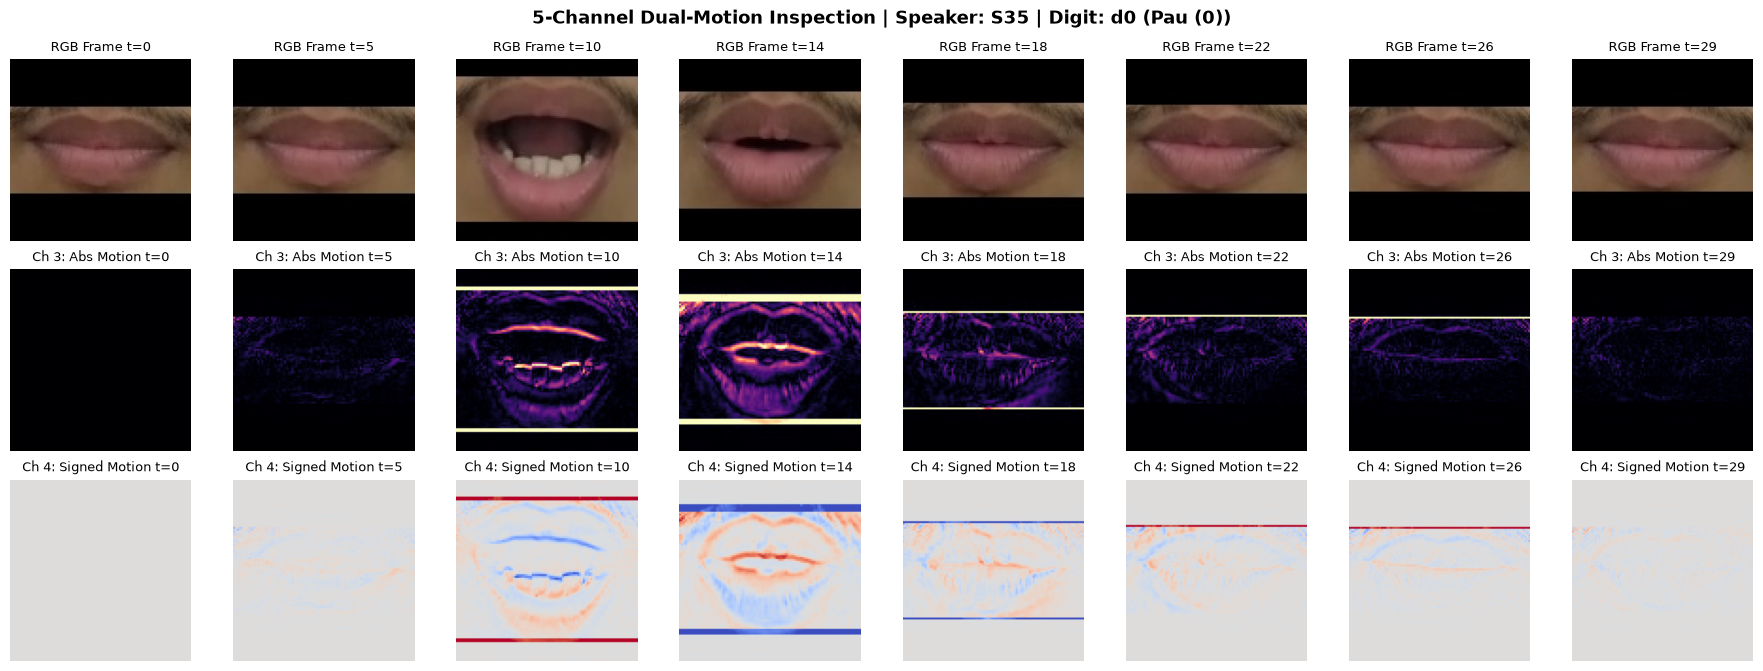

In [8]:
# Section 8: Dual-Motion Channel Visualizer
sample_idx = 0
sample_seq = X_val_5ch[sample_idx]
sample_digit = ID_TO_CLASS[y_val[sample_idx]]
sample_spk = df_val.loc[sample_idx, "speaker"]

vis_frames = [0, 5, 10, 14, 18, 22, 26, 29]
fig, axes = plt.subplots(3, len(vis_frames), figsize=(18, 6.8))
fig.suptitle(
    f"5-Channel Dual-Motion Inspection | Speaker: {sample_spk} | Digit: {sample_digit} ({DIGIT_NAMES[sample_digit]})",
    fontsize=13, fontweight="bold"
)

for col, t in enumerate(vis_frames):
    # RGB
    axes[0, col].imshow(sample_seq[t, ..., :3].astype(np.uint8))
    axes[0, col].set_title(f"RGB Frame t={t}", fontsize=9)
    axes[0, col].axis("off")
    
    # Channel 3: Absolute optical velocity
    axes[1, col].imshow(sample_seq[t, ..., 3], cmap="magma", vmin=0, vmax=60)
    axes[1, col].set_title(f"Ch 3: Abs Motion t={t}", fontsize=9)
    axes[1, col].axis("off")
    
    # Channel 4: Signed optical velocity
    axes[2, col].imshow(sample_seq[t, ..., 4], cmap="coolwarm", vmin=90, vmax=165)
    axes[2, col].set_title(f"Ch 4: Signed Motion t={t}", fontsize=9)
    axes[2, col].axis("off")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "dual_motion_channel_inspection.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Custom Layers: Speaker Neutralizer, Calibrated Tri-Window Pooling & Focal Loss


In [9]:
# Section 9: Custom Layers & Categorical Focal Loss

@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class UtteranceSpeakerNeutralizer(layers.Layer):
    """
    Subtracts the temporal mean feature vector across T=30 frames per utterance
    using a learnable sigmoid gate to eliminate static speaker appearance bias.
    """
    def __init__(self, init_logit: float = 0.85, **kwargs):
        super().__init__(**kwargs)
        self.init_logit = float(init_logit)

    def build(self, input_shape):
        self.gate_logit = self.add_weight(
            name="speaker_mean_gate_logit",
            shape=(1, 1, input_shape[-1]),
            initializer=keras.initializers.Constant(self.init_logit),
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        temporal_mean = tf.reduce_mean(inputs, axis=1, keepdims=True)  # (B, 1, D)
        gate = tf.nn.sigmoid(self.gate_logit)
        return inputs - gate * temporal_mean

    def get_config(self):
        config = super().get_config()
        config.update({"init_logit": self.init_logit})
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TemporalAttentionPooling(layers.Layer):
    """
    Learnable additive temporal attention pooling over a sequence segment (B, T_w, D).
    """
    def __init__(self, attn_units: int = 64, **kwargs):
        super().__init__(**kwargs)
        self.attn_units = attn_units
        self.dense1 = layers.Dense(attn_units, activation="tanh", name="w_attn")
        self.dense2 = layers.Dense(1, use_bias=False, name="u_attn")

    def call(self, inputs):
        score = self.dense1(inputs)         # (B, T_w, attn_units)
        logits = self.dense2(score)         # (B, T_w, 1)
        weights = tf.nn.softmax(logits, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1) # (B, D)

    def get_config(self):
        config = super().get_config()
        config.update({"attn_units": self.attn_units})
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TriWindowAttentionPooling(layers.Layer):
    """
    Partitions a (B, 30, D) sequence into kinematically calibrated sub-windows:
    Onset (0..10), Nucleus (7..19), and Coda (13..30).
    Applies independent TemporalAttentionPooling to each and concatenates into (B, 3 * D).
    """
    def __init__(
        self,
        onset_bounds: tuple = ONSET_WINDOW,
        nucleus_bounds: tuple = NUCLEUS_WINDOW,
        coda_bounds: tuple = CODA_WINDOW,
        attn_units: int = 64,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.onset_bounds = tuple(onset_bounds)
        self.nucleus_bounds = tuple(nucleus_bounds)
        self.coda_bounds = tuple(coda_bounds)
        self.attn_units = attn_units
        self.onset_pool = TemporalAttentionPooling(attn_units=attn_units, name="onset_attn")
        self.nucleus_pool = TemporalAttentionPooling(attn_units=attn_units, name="nucleus_attn")
        self.coda_pool = TemporalAttentionPooling(attn_units=attn_units, name="coda_attn")

    def call(self, inputs):
        x_onset = inputs[:, self.onset_bounds[0]:self.onset_bounds[1], :]
        x_nucleus = inputs[:, self.nucleus_bounds[0]:self.nucleus_bounds[1], :]
        x_coda = inputs[:, self.coda_bounds[0]:self.coda_bounds[1], :]

        v_onset = self.onset_pool(x_onset)
        v_nucleus = self.nucleus_pool(x_nucleus)
        v_coda = self.coda_pool(x_coda)
        return tf.concat([v_onset, v_nucleus, v_coda], axis=-1)

    def get_config(self):
        config = super().get_config()
        config.update({
            "onset_bounds": self.onset_bounds,
            "nucleus_bounds": self.nucleus_bounds,
            "coda_bounds": self.coda_bounds,
            "attn_units": self.attn_units
        })
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class CategoricalFocalLoss(keras.losses.Loss):
    """
    Multi-class Categorical Focal Loss with Label Smoothing.
    """
    def __init__(
        self,
        gamma: float = FOCAL_GAMMA,
        alpha: float = FOCAL_ALPHA,
        label_smoothing: float = LABEL_SMOOTHING,
        name: str = "categorical_focal_loss",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)
        self.gamma = float(gamma)
        self.alpha = float(alpha)
        self.label_smoothing = float(label_smoothing)

    def call(self, y_true, y_pred):
        eps = keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
        num_classes = tf.shape(y_pred)[-1]
        
        y_true_rank = len(y_true.shape)
        if y_true_rank is not None and y_true_rank == 1:
            y_true = tf.one_hot(tf.cast(y_true, tf.int32), depth=num_classes)
        elif y_true_rank is not None and y_true_rank == 2 and y_true.shape[-1] == 1:
            y_true = tf.one_hot(tf.cast(tf.squeeze(y_true, axis=-1), tf.int32), depth=num_classes)
            
        y_true = tf.cast(y_true, y_pred.dtype)
        
        if self.label_smoothing > 0.0:
            c = tf.cast(num_classes, y_pred.dtype)
            y_true = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / c)
            
        focal_weight = tf.pow(1.0 - y_pred, self.gamma)
        cross_entropy = -tf.math.log(y_pred)
        loss = self.alpha * focal_weight * cross_entropy
        per_sample_loss = tf.reduce_sum(y_true * loss, axis=-1)
        return tf.reduce_mean(per_sample_loss)

    def get_config(self):
        config = super().get_config()
        config.update({
            "gamma": self.gamma,
            "alpha": self.alpha,
            "label_smoothing": self.label_smoothing,
        })
        return config

print("Custom Layers & Focal Loss compiled successfully.")


Custom Layers & Focal Loss compiled successfully.


## 10. Model Assembly: 5-Channel Dual-Motion Stem Adapter + EfficientNet-B0 + BiGRU + Calibrated Tri-Window Head
- **5-Channel 1x1 Stem Adapter**: Initialized with Identity on RGB ($W_{0,0}=1, W_{1,1}=1, W_{2,2}=1$) and an injection gain of $+0.10$ on both Channel 3 (Absolute Motion) and Channel 4 (Signed Motion).
- **UtteranceSpeakerNeutralizer**: Removes static speaker bias directly after spatial pooling.
- **BiGRU**: 128 units forward + 128 units backward (256 spatiotemporal features per frame).
- **Calibrated Tri-Window Attention Head**: Combines Onset ($0..10$), Nucleus ($7..19$), and Coda ($13..30$) into a rich 768-D representation.


In [10]:
# Section 10: Model Builder Function

def build_calibrated_triwindow_dual_motion_model() -> tuple[keras.Model, keras.Model]:
    frame_in = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="frame_5ch_input")
    
    # 1. 1x1 Motion Stem Adapter (maps 5 channels to 3 channels)
    adapter = layers.Conv2D(
        filters=3,
        kernel_size=(1, 1),
        padding="same",
        use_bias=False,
        name="dual_motion_stem_adapter"
    )
    adapted_rgb = adapter(frame_in)
    
    # 2. Pretrained EfficientNetB0 (ImageNet weights, frozen in Stage 1)
    base_cnn = keras.applications.EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3)
    )
    base_cnn.trainable = False
    
    preprocessed = keras.applications.efficientnet.preprocess_input(adapted_rgb)
    cnn_features = base_cnn(preprocessed)
    pooled = layers.GlobalAveragePooling2D(name="gap")(cnn_features)  # (batch, 1280)
    extractor = keras.Model(inputs=frame_in, outputs=pooled, name="EfficientNetB0_5Ch_Extractor")
    
    # Initialize adapter weights: Identity on RGB, 0.10 on Abs Motion, 0.10 on Signed Motion
    w = np.zeros((1, 1, 5, 3), dtype=np.float32)
    w[0, 0, 0, 0] = 1.0  # R -> R
    w[0, 0, 1, 1] = 1.0  # G -> G
    w[0, 0, 2, 2] = 1.0  # B -> B
    w[0, 0, 3, :] = 0.10 # Abs motion energy
    w[0, 0, 4, :] = 0.10 # Signed motion polarity
    adapter.set_weights([w])
    
    # Sequence Architecture Assembly
    seq_input = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="sequence_5ch_input")
    
    # 3. Frame Feature Extraction
    x = layers.TimeDistributed(extractor, name="time_distributed_cnn")(seq_input)  # (batch, 30, 1280)
    
    # 4. Utterance-Level Speaker Neutralization
    x = UtteranceSpeakerNeutralizer(name="utterance_speaker_neutralizer")(x)
    x = layers.LayerNormalization(name="post_neutralizer_ln")(x)
    
    # 5. Spatial Feature Projection
    x = layers.TimeDistributed(
        layers.Dense(PROJECTION_DIM, activation="swish", name="projection_dense"),
        name="td_spatial_projection"
    )(x)
    x = layers.SpatialDropout1D(0.20, name="spatial_dropout_1d")(x)
    
    # 6. Bidirectional GRU Sequence Modeling
    x = layers.Bidirectional(
        layers.GRU(GRU_UNITS, return_sequences=True, dropout=GRU_DROPOUT, name="gru_layer"),
        name="bigru_temporal_encoder"
    )(x)  # (batch, 30, 256)
    x = layers.LayerNormalization(name="post_bigru_ln")(x)
    
    # 7. Calibrated Phonetic Tri-Window Attention Pooling (Onset + Nucleus + Coda -> 768-D)
    x = TriWindowAttentionPooling(
        onset_bounds=ONSET_WINDOW,
        nucleus_bounds=NUCLEUS_WINDOW,
        coda_bounds=CODA_WINDOW,
        attn_units=64,
        name="calibrated_triwindow_pooling"
    )(x)  # (batch, 768)
    
    # 8. Classification Head
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(HEAD_DROPOUT, name="head_dropout_1")(x)
    x = layers.Dense(256, activation="swish", name="head_dense_256")(x)
    x = layers.Dropout(0.25, name="head_dropout_2")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)
    
    model = keras.Model(inputs=seq_input, outputs=outputs, name="EfficientNetB0_BiGRU_CalibratedTriWindow_VSR")
    return model, base_cnn

model, base_cnn = build_calibrated_triwindow_dual_motion_model()
print("=" * 80)
print("MODEL ARCHITECTURE ASSEMBLY COMPLETE")
print("=" * 80)
print(f"Total Parameters          : {model.count_params():,}")
print(f"Trainable Parameters (S1) : {sum(w.shape.num_elements() for w in model.trainable_weights):,}")
print(f"Input Sequence Shape      : {model.input_shape}")
print(f"Output Probabilities Shape: {model.output_shape}")
print("=" * 80)


MODEL ARCHITECTURE ASSEMBLY COMPLETE
Total Parameters          : 4,930,621
Trainable Parameters (S1) : 879,514
Input Sequence Shape      : (None, 30, 96, 96, 5)
Output Probabilities Shape: (None, 11)


## 11. Top-$K$ Snapshot Checkpoint Callback
Saves the Top-$K$ validation checkpoints on disk for Snapshot Ensembling.


In [11]:
# Section 11: Top-K Snapshot Saver Callback

class TopKSnapshotCheckpoint(keras.callbacks.Callback):
    """
    Maintains the Top-K highest validation accuracy checkpoints on disk during training.
    """
    def __init__(self, snapshot_dir: Path, k: int = TOP_K_SNAPSHOTS, prefix: str = "stage2"):
        super().__init__()
        self.snapshot_dir = Path(snapshot_dir)
        self.k = k
        self.prefix = prefix
        self.best_snapshots = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        val_acc = logs.get("val_accuracy", 0.0)
        
        if val_loss is None:
            return
            
        epoch_num = epoch + 1
        temp_path = self.snapshot_dir / f"{self.prefix}_epoch_{epoch_num:02d}_acc_{val_acc:.4f}_loss_{val_loss:.4f}.weights.h5"
        
        if len(self.best_snapshots) < self.k or val_acc > min(s[3] for s in self.best_snapshots):
            self.model.save_weights(temp_path)
            self.best_snapshots.append((val_loss, epoch_num, temp_path, val_acc))
            self.best_snapshots.sort(key=lambda x: (-x[3], x[0]))
            
            if len(self.best_snapshots) > self.k:
                removed = self.best_snapshots.pop(-1)
                if removed[2].exists():
                    removed[2].unlink()
                    
            print(f"  [Snapshot {len(self.best_snapshots)}/{self.k}] Saved checkpoint: {temp_path.name}")


## 12. Stage 1: Warmup Training (Frozen Backbone)
Training the 5-channel adapter, speaker neutralizer, BiGRU, and calibrated Tri-Window head with `Adam(lr=1e-4)` and Categorical Focal Loss.


In [12]:
# Section 12: Stage 1 Training Execution

optimizer_s1 = keras.optimizers.Adam(learning_rate=STAGE1_LR)
loss_fn = CategoricalFocalLoss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA, label_smoothing=LABEL_SMOOTHING)

model.compile(
    optimizer=optimizer_s1,
    loss=loss_fn,
    metrics=["accuracy"]
)

callbacks_s1 = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=STAGE1_PATIENCE,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("=" * 80)
print(f"STAGE 1: WARMUP TRAINING ({STAGE1_MAX_EPOCHS} Max Epochs, LR={STAGE1_LR})")
print("=" * 80)

t0 = time.time()
history_s1 = model.fit(
    train_generator,
    validation_data=(X_val_5ch, y_val),
    epochs=STAGE1_MAX_EPOCHS,
    callbacks=callbacks_s1,
    verbose=1
)
s1_time = time.time() - t0
print(f"Stage 1 completed in {s1_time:.1f}s!")


STAGE 1: WARMUP TRAINING (30 Max Epochs, LR=0.0001)
Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.1239 - loss: 0.7151 - val_accuracy: 0.1409 - val_loss: 0.4744 - learning_rate: 1.0000e-04
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.1898 - loss: 0.5968 - val_accuracy: 0.3045 - val_loss: 0.4174 - learning_rate: 1.0000e-04
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.2693 - loss: 0.5229 - val_accuracy: 0.4136 - val_loss: 0.3811 - learning_rate: 1.0000e-04
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.2943 - loss: 0.4681 - val_accuracy: 0.3864 - val_loss: 0.3617 - learning_rate: 1.0000e-04
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.3466 - loss: 0.4413 - val_accuracy: 0.4182 - val_loss: 0.3346 - learning_rate: 1.0000e-04
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.4102 - loss: 0.3658 - val_accuracy: 0.4455 - val_loss: 0.3338 - learning_rate: 1.0000e-04
Epoch 7/30
55/55 ━━━━━━

In [13]:
# saving weights to disk
# model.save_weights(RESULTS_DIR / "stage1_warmup_backup.weights.h5")

In [14]:
# to load it
# model.load_weights(RESULTS_DIR / "stage1_warmup_backup.weights.h5")
# print("Stage 1 warmup weights loaded successfully!")

## 13. Stage 2: Fine-Tuning Top 20% EfficientNet-B0 + Snapshot Ensembling
Unfreezing the top spatial blocks under Cosine Annealing decay (`CosineDecay(1e-5)`), saving the Top 5 Checkpoints.


In [15]:
# Section 13: Stage 2 Fine-Tuning with Snapshot Ensembling

# Unfreeze top 20% layers of EfficientNet-B0
base_cnn.trainable = True
num_layers = len(base_cnn.layers)
unfreeze_start = int(num_layers * (1.0 - FINE_TUNE_FRACTION))

for idx, layer in enumerate(base_cnn.layers):
    if idx < unfreeze_start or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

print(f"EfficientNet-B0 total layers : {num_layers}")
print(f"Unfrozen top layers from index : {unfreeze_start} (Top {FINE_TUNE_FRACTION*100:.0f}%)")
print(f"Trainable Parameters (Stage 2) : {sum(w.shape.num_elements() for w in model.trainable_weights):,}")

# Cosine Annealing Learning Rate Schedule
steps_per_epoch = len(train_generator)
total_steps = STAGE2_MAX_EPOCHS * steps_per_epoch
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=STAGE2_LR,
    decay_steps=total_steps,
    alpha=0.10
)

optimizer_s2 = keras.optimizers.Adam(learning_rate=lr_schedule)
model.compile(
    optimizer=optimizer_s2,
    loss=loss_fn,
    metrics=["accuracy"]
)

snapshot_cb = TopKSnapshotCheckpoint(snapshot_dir=SNAPSHOT_DIR, k=TOP_K_SNAPSHOTS, prefix="stage2")

callbacks_s2 = [
    snapshot_cb,
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=STAGE2_PATIENCE,
        restore_best_weights=False,
        mode="max",
        verbose=1
    )
]

print("=" * 80)
print(f"STAGE 2: FINE-TUNING & SNAPSHOT ENSEMBLING ({STAGE2_MAX_EPOCHS} Max Epochs)")
print("=" * 80)

t0 = time.time()
history_s2 = model.fit(
    train_generator,
    validation_data=(X_val_5ch, y_val),
    epochs=STAGE2_MAX_EPOCHS,
    callbacks=callbacks_s2,
    verbose=1
)
s2_time = time.time() - t0
print(f"Stage 2 completed in {s2_time:.1f}s!")


EfficientNet-B0 total layers : 238
Unfrozen top layers from index : 190 (Top 20%)
Trainable Parameters (Stage 2) : 3,167,018
STAGE 2: FINE-TUNING & SNAPSHOT ENSEMBLING (25 Max Epochs)
Epoch 1/25
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8227 - loss: 0.1322  [Snapshot 1/5] Saved checkpoint: stage2_epoch_01_acc_0.6545_loss_0.2241.weights.h5
55/55 ━━━━━━━━━━━━━━━━━━━━ 295s 3s/step - accuracy: 0.8227 - loss: 0.1322 - val_accuracy: 0.6545 - val_loss: 0.2241
Epoch 2/25
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8398 - loss: 0.1219  [Snapshot 2/5] Saved checkpoint: stage2_epoch_02_acc_0.6591_loss_0.2223.weights.h5
55/55 ━━━━━━━━━━━━━━━━━━━━ 146s 3s/step - accuracy: 0.8398 - loss: 0.1219 - val_accuracy: 0.6591 - val_loss: 0.2223
Epoch 3/25
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8250 - loss: 0.1295  [Snapshot 3/5] Saved checkpoint: stage2_epoch_03_acc_0.6545_loss_0.2218.weights.h5
55/55 ━━━━━━━━━━━━━━━━━━━━ 138s 3s/step - accuracy: 0.8250 - loss: 0.1295 - val_acc

## 14. Training History Curves
Plotting training and validation loss and accuracy across both stages.


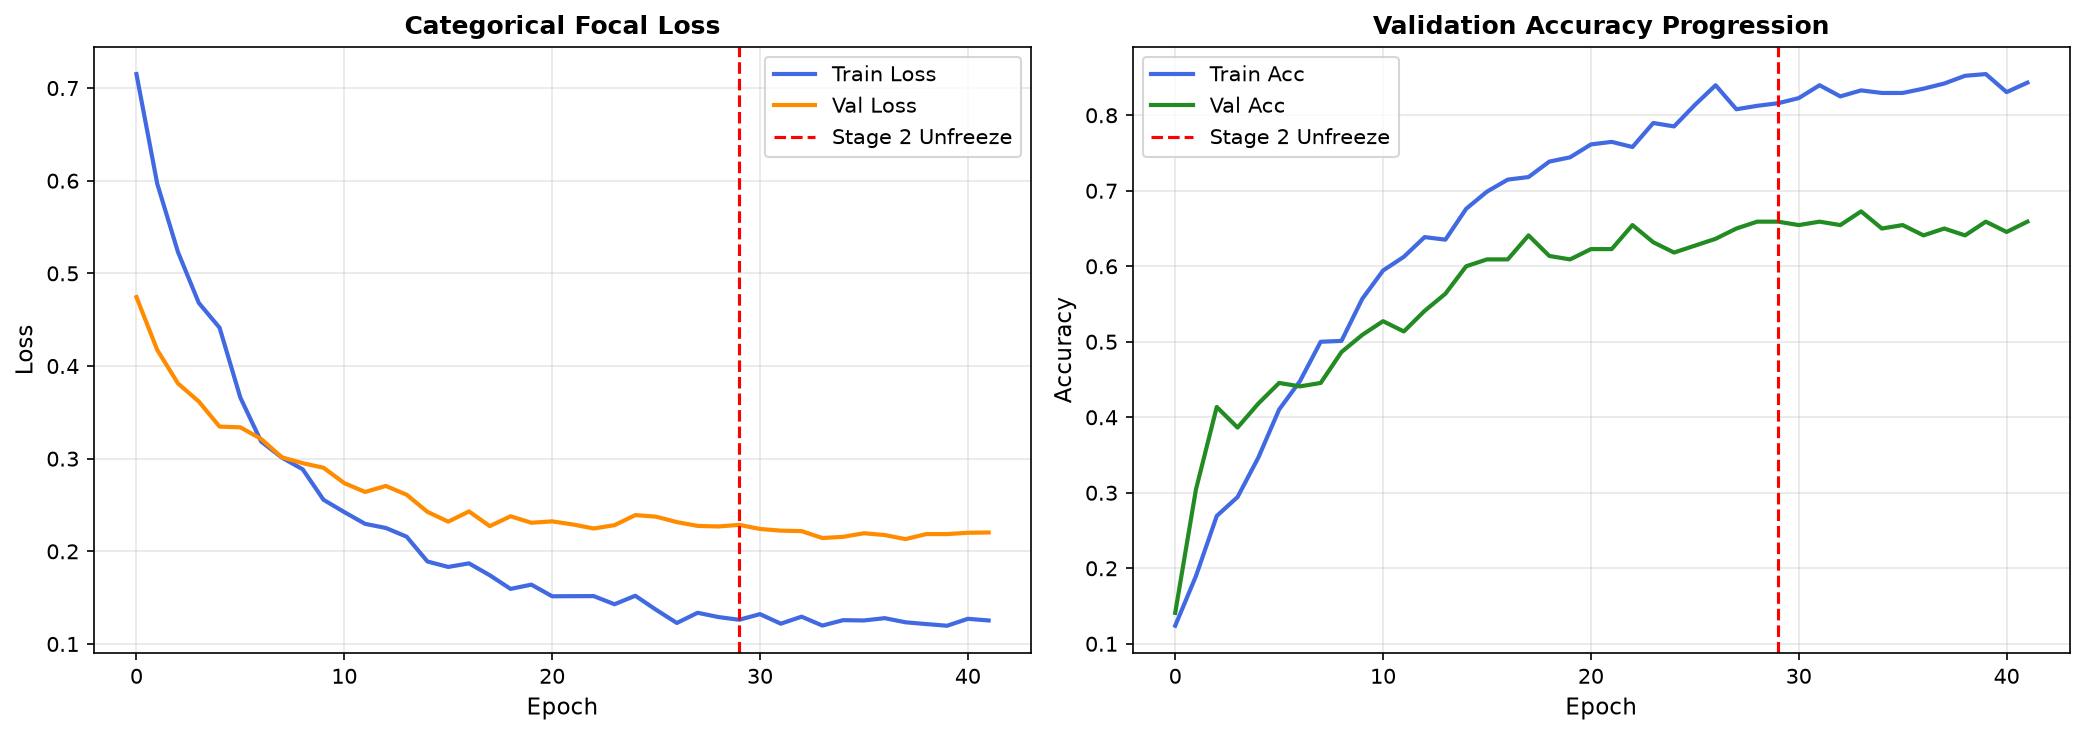

In [16]:
# Section 14: Training Curves Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Loss curve
axes[0].plot(history_s1.history["loss"] + history_s2.history["loss"], label="Train Loss", color="royalblue", lw=2)
axes[0].plot(history_s1.history["val_loss"] + history_s2.history["val_loss"], label="Val Loss", color="darkorange", lw=2)
axes[0].axvline(len(history_s1.history["loss"]) - 1, color="red", linestyle="--", label="Stage 2 Unfreeze")
axes[0].set_title("Categorical Focal Loss", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(history_s1.history["accuracy"] + history_s2.history["accuracy"], label="Train Acc", color="royalblue", lw=2)
axes[1].plot(history_s1.history["val_accuracy"] + history_s2.history["val_accuracy"], label="Val Acc", color="forestgreen", lw=2)
axes[1].axvline(len(history_s1.history["accuracy"]) - 1, color="red", linestyle="--", label="Stage 2 Unfreeze")
axes[1].set_title("Validation Accuracy Progression", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves.png", dpi=150)
plt.show()


## 15. 4-View Test-Time Augmentation (TTA)
Evaluating all 5 saved snapshot checkpoints with 4 canonical views:
1. **View 1 (Identity)**: Original sequence
2. **View 2 (Temporal Shift $+1$)**: Forward time lag
3. **View 3 (Temporal Shift $-1$)**: Backward time lead
4. **View 4 (Horizontal Flip)**: Mirrored mouth geometry


In [17]:
# Section 15: 4-View TTA Inference Pipeline

def generate_4view_tta(X_seq: np.ndarray) -> List[np.ndarray]:
    v1 = X_seq.copy()
    v2 = np.empty_like(X_seq)
    v2[:-1] = X_seq[1:]
    v2[-1] = X_seq[-1]
    v3 = np.empty_like(X_seq)
    v3[0] = X_seq[0]
    v3[1:] = X_seq[:-1]
    v4 = np.flip(X_seq, axis=2).copy()
    return [v1, v2, v3, v4]

N_val = len(X_val_5ch)
views_5ch = [np.zeros_like(X_val_5ch) for _ in range(4)]

for i in range(N_val):
    v_list = generate_4view_tta(X_val_5ch[i])
    for v in range(4):
        views_5ch[v][i] = v_list[v]

print("Precomputed 4-View TTA batches for all validation sequences.")

# Discover saved snapshot checkpoints
snapshot_paths = sorted(list(SNAPSHOT_DIR.glob("*.weights.h5")))
print(f"Discovered {len(snapshot_paths)} snapshot checkpoints:")
for sp in snapshot_paths:
    print(f"  • {sp.name}")

# Run TTA across all snapshots
snapshot_probs = []
for idx, sp in enumerate(snapshot_paths, 1):
    model.load_weights(sp)
    v_probs = [model.predict(v, batch_size=16, verbose=0) for v in views_5ch]
    snap_p = np.mean(v_probs, axis=0)
    snapshot_probs.append(snap_p)
    snap_acc = accuracy_score(y_val, np.argmax(snap_p, axis=1))
    print(f"  -> Snapshot {idx}/{len(snapshot_paths)} ({sp.name[:28]}): 4-View TTA Acc = {snap_acc * 100:.2f}%")

final_probs = np.mean(snapshot_probs, axis=0)
final_preds = np.argmax(final_probs, axis=1)
final_acc = accuracy_score(y_val, final_preds)

print("=" * 80)
print(f"🏆 EXPERIMENT 23 FINAL RESULTS (5-Snapshot + 4-View TTA):")
print(f"   Accuracy : {final_acc * 100:.2f}% ({np.sum(final_preds == y_val)}/{N_val})")
print("=" * 80)


Precomputed 4-View TTA batches for all validation sequences.
Discovered 5 snapshot checkpoints:
  • stage2_epoch_02_acc_0.6591_loss_0.2223.weights.h5
  • stage2_epoch_04_acc_0.6727_loss_0.2143.weights.h5
  • stage2_epoch_06_acc_0.6545_loss_0.2195.weights.h5
  • stage2_epoch_10_acc_0.6591_loss_0.2186.weights.h5
  • stage2_epoch_12_acc_0.6591_loss_0.2203.weights.h5
  -> Snapshot 1/5 (stage2_epoch_02_acc_0.6591_l): 4-View TTA Acc = 66.82%
  -> Snapshot 2/5 (stage2_epoch_04_acc_0.6727_l): 4-View TTA Acc = 68.18%
  -> Snapshot 3/5 (stage2_epoch_06_acc_0.6545_l): 4-View TTA Acc = 65.91%
  -> Snapshot 4/5 (stage2_epoch_10_acc_0.6591_l): 4-View TTA Acc = 66.82%
  -> Snapshot 5/5 (stage2_epoch_12_acc_0.6591_l): 4-View TTA Acc = 66.36%
🏆 EXPERIMENT 23 FINAL RESULTS (5-Snapshot + 4-View TTA):
   Accuracy : 67.27% (148/220)


## 16. Speaker Breakdown & Classification Report
Evaluating generalization across all 6 base validation speakers and all 11 classes.


In [18]:
# Section 16: Evaluation Metrics & Speaker Breakdown
df_val["pred_digit_id"] = final_preds
df_val["pred_digit"] = [ID_TO_CLASS[p] for p in final_preds]
df_val["is_correct"] = (final_preds == y_val)

spk_breakdown = {}
print("=" * 80)
print("PER-SPEAKER GENERALIZATION BREAKDOWN")
print("=" * 80)
for spk in sorted(df_val["base_speaker"].unique()):
    sub = df_val[df_val["base_speaker"] == spk]
    c = int(sub["is_correct"].sum())
    tot = len(sub)
    spk_acc = c / tot
    spk_breakdown[spk] = {
        "correct": c,
        "total": tot,
        "accuracy": float(spk_acc)
    }
    print(f"  Speaker {spk:<6}: {c:2d}/{tot:2d} correct -> {spk_acc * 100:6.2f}%")

print("=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)
cls_report = classification_report(
    y_val, final_preds,
    target_names=[f"{DIGIT_NAMES[f'd{i}']}" for i in range(11)],
    digits=4,
    output_dict=True
)
print(classification_report(
    y_val, final_preds,
    target_names=[f"{DIGIT_NAMES[f'd{i}']}" for i in range(11)],
    digits=4
))


PER-SPEAKER GENERALIZATION BREAKDOWN
  Speaker S35   : 29/44 correct ->  65.91%
  Speaker S38   : 19/33 correct ->  57.58%
  Speaker s34   : 33/44 correct ->  75.00%
  Speaker s45   : 21/33 correct ->  63.64%
  Speaker s47   : 26/33 correct ->  78.79%
  Speaker s48   : 20/33 correct ->  60.61%
CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Pau (0)     0.6154    0.8000    0.6957        20
    Nung (1)     0.8000    0.6000    0.6857        20
   Saung (2)     0.4545    0.2500    0.3226        20
     Sam (3)     0.7500    0.7500    0.7500        20
      Si (4)     0.5455    0.9000    0.6792        20
      Ha (5)     0.8500    0.8500    0.8500        20
     Hok (6)     1.0000    0.7500    0.8571        20
    Chit (7)     0.6471    0.5500    0.5946        20
     Pet (8)     0.6667    0.9000    0.7660        20
     Kao (9)     0.4000    0.5000    0.4444        20
    Sip (10)     1.0000    0.5500    0.7097        20

    accuracy                     

## 17. Confusion Matrix Visualization


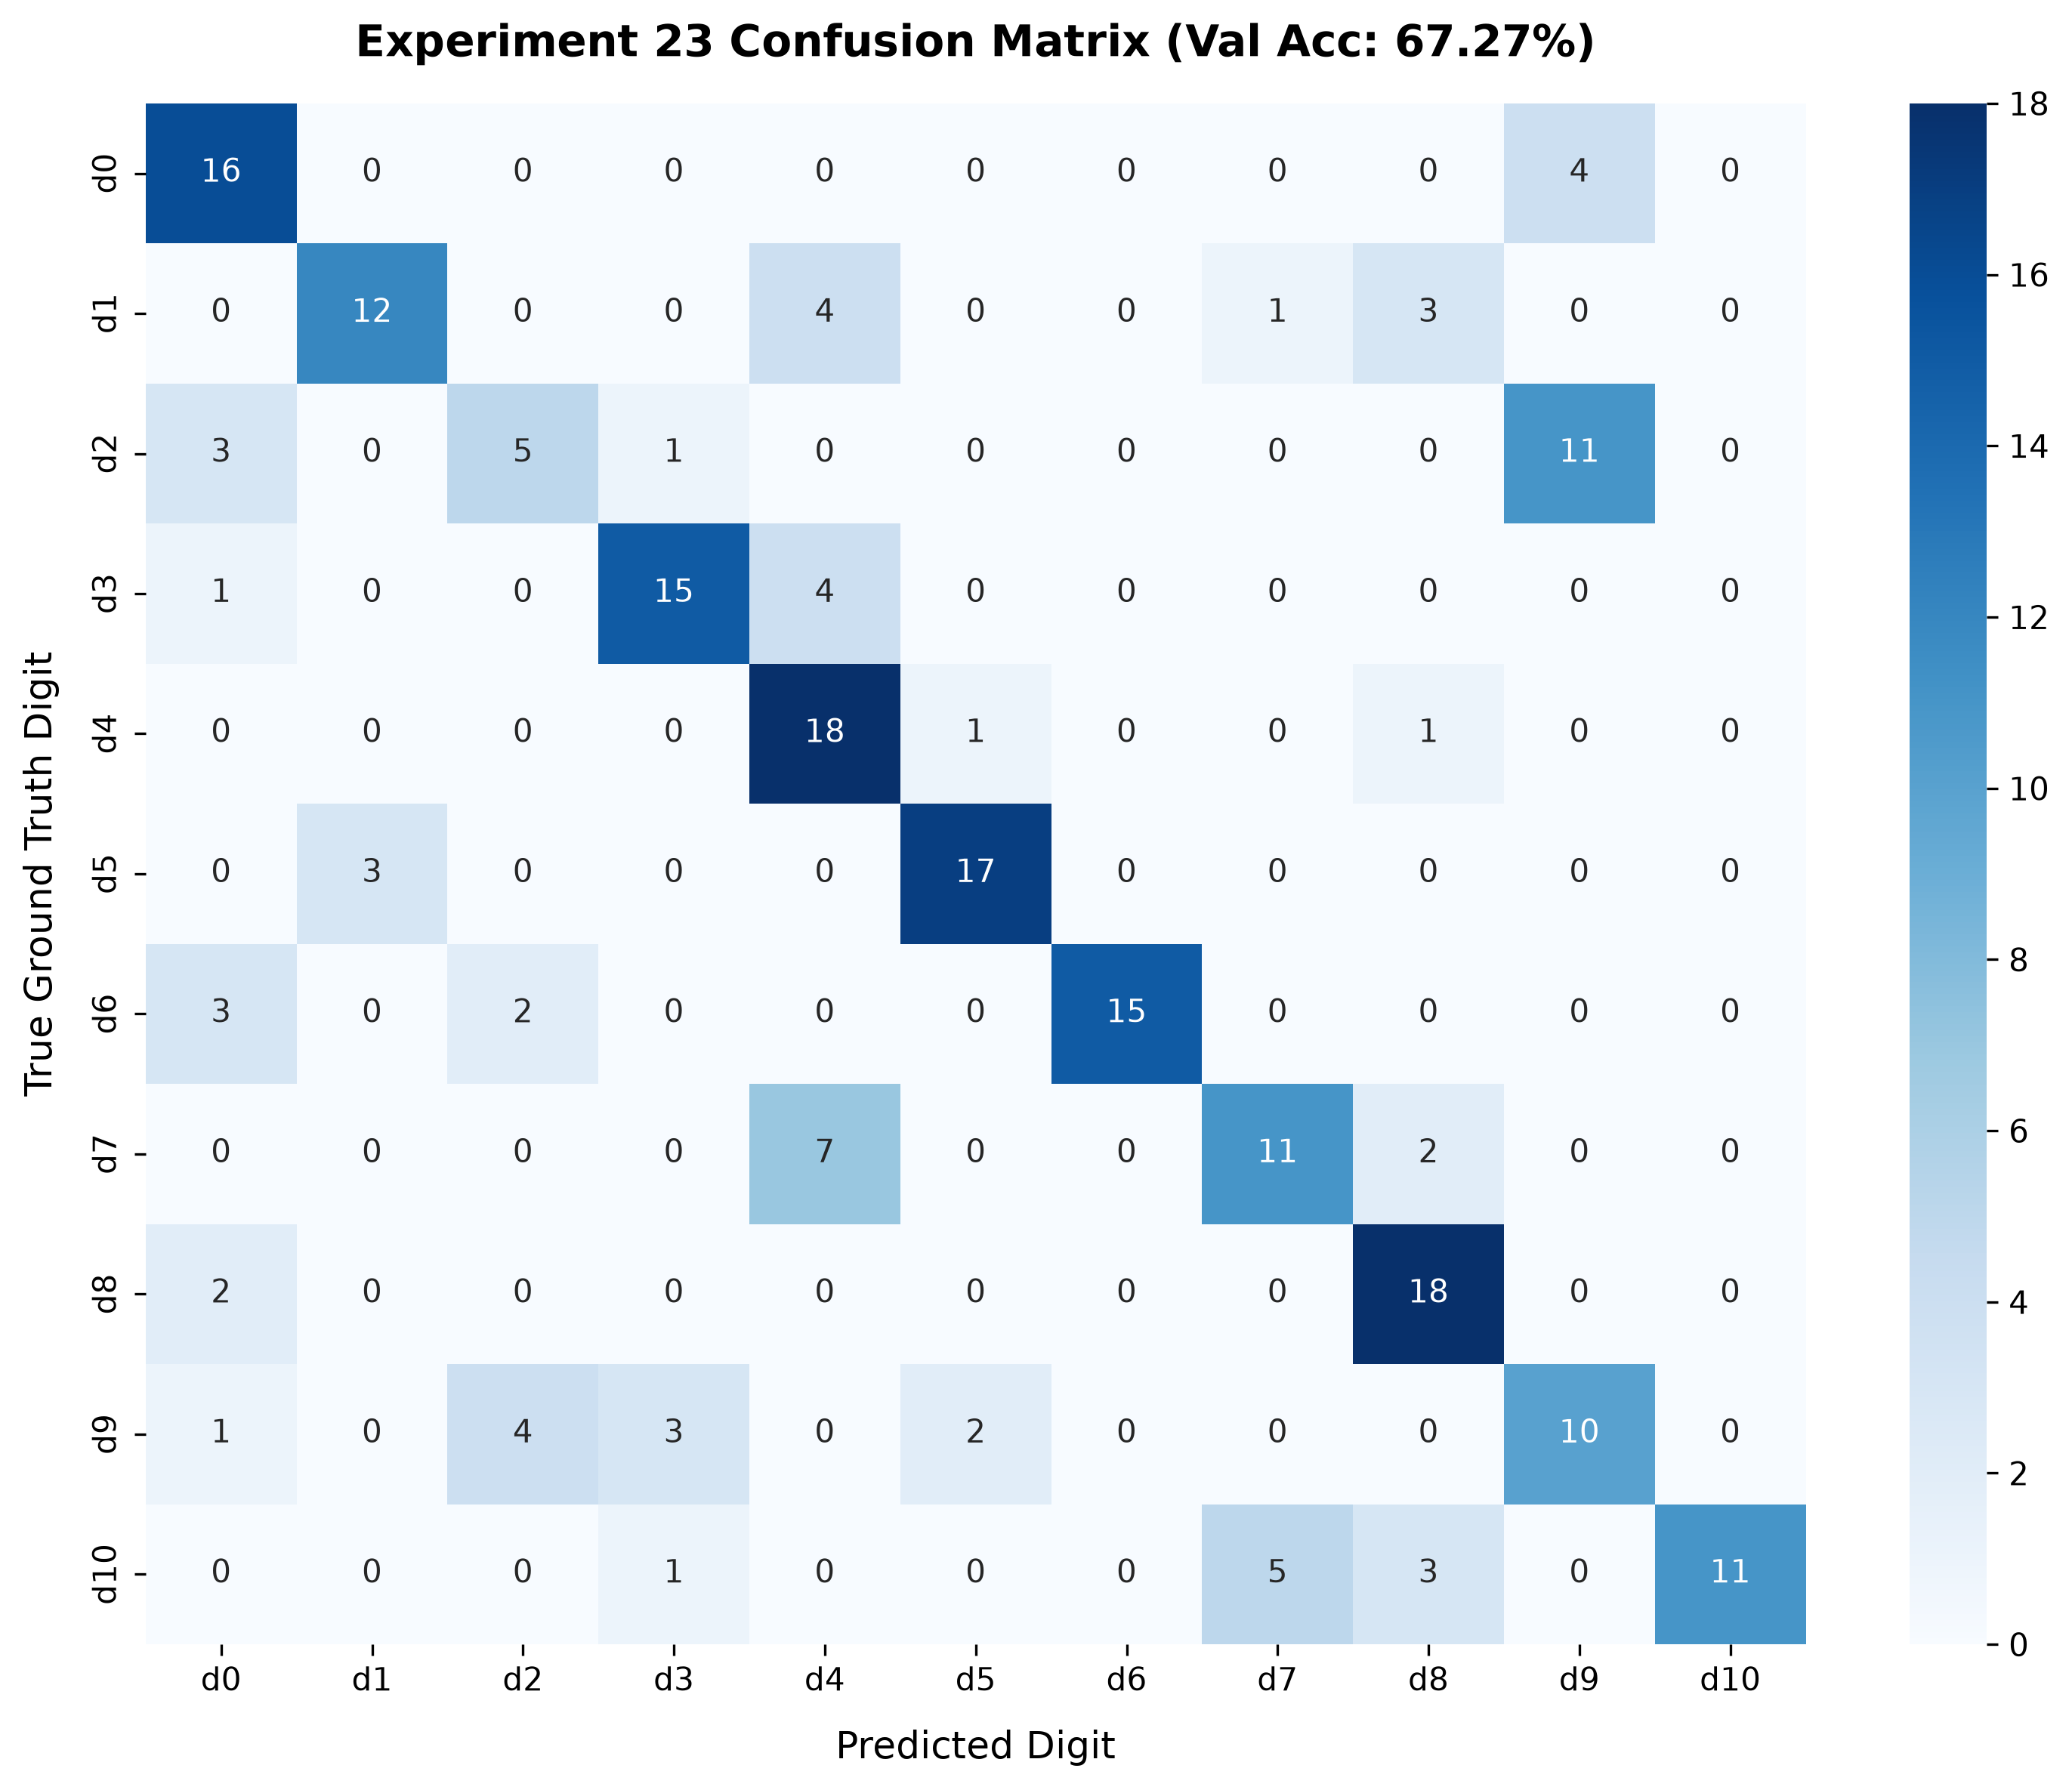

Saved confusion matrix plot to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20/confusion_matrix.png


In [19]:
# Section 17: Confusion Matrix
cm = confusion_matrix(y_val, final_preds)
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[f"d{i}" for i in range(11)],
    yticklabels=[f"d{i}" for i in range(11)],
    ax=ax, cbar=True
)
ax.set_title(f"Experiment 23 Confusion Matrix (Val Acc: {final_acc*100:.2f}%)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Predicted Digit", fontsize=12, labelpad=10)
ax.set_ylabel("True Ground Truth Digit", fontsize=12, labelpad=10)
plt.tight_layout()
cm_path = RESULTS_DIR / "confusion_matrix.png"
plt.savefig(cm_path)
plt.show()
print(f"Saved confusion matrix plot to: {cm_path}")


## 18. Export Metrics & Utterance Predictions
Saving all metrics, classifications, and per-utterance predictions to `results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20/`.


In [20]:
# Section 18: Artifact Export
metrics = {
    "experiment_name": "efficientnetb0_bigru_calibrated_triwindow_dual_motion",
    "val_accuracy": float(final_acc),
    "correct_samples": int(np.sum(final_preds == y_val)),
    "total_samples": int(N_val),
    "macro_f1": float(cls_report["macro avg"]["f1-score"]),
    "weighted_f1": float(cls_report["weighted avg"]["f1-score"]),
    "calibrated_windows": {
        "onset": list(ONSET_WINDOW),
        "nucleus": list(NUCLEUS_WINDOW),
        "coda": list(CODA_WINDOW)
    },
    "dual_motion_channels": 5,
    "per_speaker_accuracy": spk_breakdown
}

with open(RESULTS_DIR / "metrics_80_20.json", "w") as f:
    json.dump(metrics, f, indent=2)

with open(RESULTS_DIR / "classification_report.json", "w") as f:
    json.dump(cls_report, f, indent=2)

with open(RESULTS_DIR / "per_speaker_breakdown.json", "w") as f:
    json.dump(spk_breakdown, f, indent=2)

df_val.to_csv(RESULTS_DIR / "utterance_predictions.csv", index=False)

print("=" * 80)
print(f"ALL EXPERIMENT 23 ARTIFACTS EXPORTED TO: {RESULTS_DIR}")
print("=" * 80)


ALL EXPERIMENT 23 ARTIFACTS EXPORTED TO: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_calibrated_triwindow_dual_motion_80_20
